In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

output_dir = Path("../outputs")
output_dir.mkdir(parents=True, exist_ok=True)

results_path = output_dir / "day50_automated_quality_results.csv"

results_df = pd.read_csv(results_path)

print("Dataset shape:", results_df.shape)
print("Columns:", results_df.columns.tolist())

display(results_df.head())

Dataset shape: (15, 6)
Columns: ['inactive_sensors', 'inactive_percentage', 'method', 'SNR_dB', 'PSNR_dB', 'SSIM']


,inactive_sensors,inactive_percentage,method,SNR_dB,PSNR_dB,SSIM
0,0,0.0,Incomplete,inf,inf,1.000000
1,0,0.0,Linear,inf,inf,1.000000
2,0,0.0,Cubic Spline,inf,inf,1.000000
3,4,12.5,Incomplete,17.769405,27.297903,0.974596
4,4,12.5,Linear,57.256457,66.784955,0.999973


In [2]:
print("Missing values:")
print(results_df.isnull().sum())

print("\nMethods:")
print(results_df["method"].unique())

print("\nInactive sensor counts:")
print(sorted(results_df["inactive_sensors"].unique()))

Missing values:
inactive_sensors       0
inactive_percentage    0
method                 0
SNR_dB                 0
PSNR_dB                0
SSIM                   0
dtype: int64

Methods:
<StringArray>
['Incomplete', 'Linear', 'Cubic Spline']
Length: 3, dtype: str

Inactive sensor counts:
[np.int64(0), np.int64(4), np.int64(8), np.int64(12), np.int64(16)]


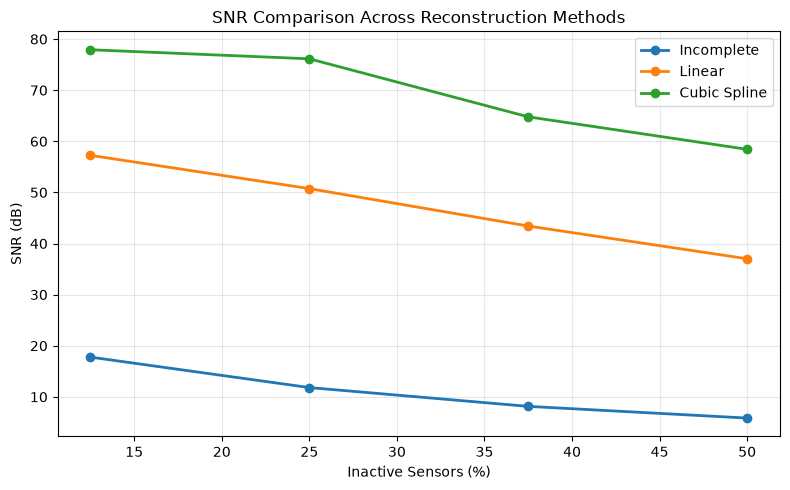

In [3]:
plt.figure(figsize=(8, 5))

for method in ["Incomplete", "Linear", "Cubic Spline"]:
    subset = results_df[results_df["method"] == method].sort_values(
        "inactive_percentage"
    )

    plt.plot(
        subset["inactive_percentage"],
        subset["SNR_dB"],
        marker="o",
        linewidth=2,
        label=method
    )

plt.xlabel("Inactive Sensors (%)")
plt.ylabel("SNR (dB)")
plt.title("SNR Comparison Across Reconstruction Methods")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()

plt.savefig(
    output_dir / "day51_snr_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

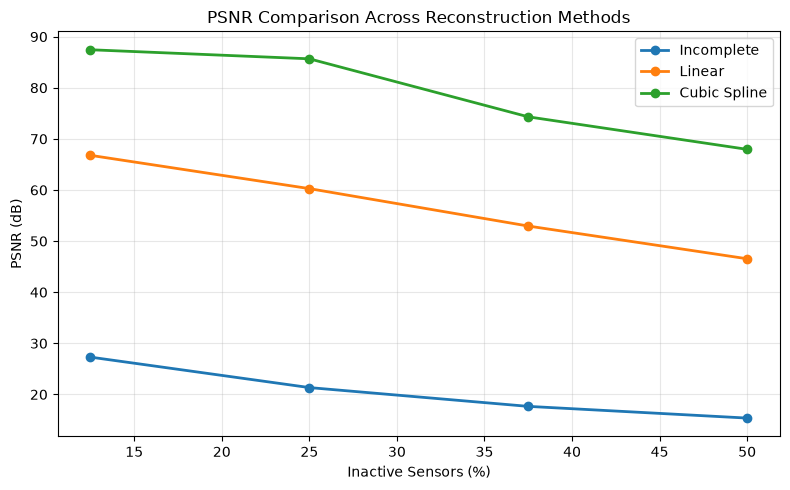

In [4]:
plt.figure(figsize=(8, 5))

for method in ["Incomplete", "Linear", "Cubic Spline"]:
    subset = results_df[results_df["method"] == method].sort_values(
        "inactive_percentage"
    )

    plt.plot(
        subset["inactive_percentage"],
        subset["PSNR_dB"],
        marker="o",
        linewidth=2,
        label=method
    )

plt.xlabel("Inactive Sensors (%)")
plt.ylabel("PSNR (dB)")
plt.title("PSNR Comparison Across Reconstruction Methods")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()

plt.savefig(
    output_dir / "day51_psnr_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

In [6]:
ssim_table = results_df.pivot(
    index="inactive_percentage",
    columns="method",
    values="SSIM"
)

display(ssim_table.round(6))

method,Cubic Spline,Incomplete,Linear
inactive_percentage,,,
0.0,1.000000,1.000000,1.000000
12.5,1.000000,0.974596,0.999973
25.0,1.000000,0.928679,0.999932
37.5,0.999995,0.821022,0.999758
50.0,0.999985,0.743259,0.998651


In [7]:
print("Minimum SSIM:", results_df["SSIM"].min())
print("Maximum SSIM:", results_df["SSIM"].max())

print("\nSSIM values outside [-1, 1]:")
print(
    results_df[
        (results_df["SSIM"] < -1) |
        (results_df["SSIM"] > 1)
    ]
)

Minimum SSIM: 0.7432594377749272
Maximum SSIM: 1.0

SSIM values outside [-1, 1]:
Empty DataFrame
Columns: [inactive_sensors, inactive_percentage, method, SNR_dB, PSNR_dB, SSIM]
Index: []


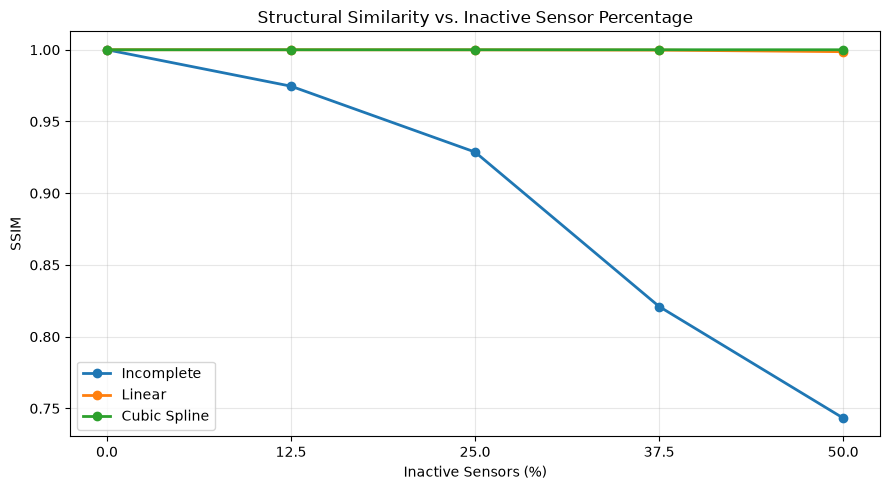

In [8]:
plt.figure(figsize=(9, 5))

for method in ["Incomplete", "Linear", "Cubic Spline"]:
    subset = results_df[
        results_df["method"] == method
    ].sort_values("inactive_percentage")

    plt.plot(
        subset["inactive_percentage"],
        subset["SSIM"],
        marker="o",
        linewidth=2,
        label=method
    )

plt.xlabel("Inactive Sensors (%)")
plt.ylabel("SSIM")
plt.title("Structural Similarity vs. Inactive Sensor Percentage")
plt.xticks([0, 12.5, 25, 37.5, 50])
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()

plt.savefig(
    output_dir / "day51_ssim_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()